<a href="https://colab.research.google.com/github/anasabrinars/Fase-1-FIAP/blob/main/Crescimento_e_Receita.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
#imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#bases

df_orders = pd.read_csv('/olist_orders_dataset[1].csv')
df_pagamentos = pd.read_csv('/olist_order_payments_dataset[1].csv')

In [22]:
#verificando coluna data

df_orders['order_purchase_timestamp'] = pd.to_datetime(
    df_orders['order_purchase_timestamp'],
    dayfirst=True,
    errors='coerce'
)

In [23]:
print(df_orders['order_purchase_timestamp'].dtype)

datetime64[ns]


In [24]:
#qtde pedidos mensais

pedidos_mensais = (
    df_orders.groupby(
        df_orders['order_purchase_timestamp'].dt.to_period('M')
    )['order_id']
    .nunique()
    .reset_index()
)

pedidos_mensais.columns = ['mes', 'quantidade_pedidos']

print(pedidos_mensais)

        mes  quantidade_pedidos
0   2016-02                   1
1   2016-03                   8
2   2016-04                  64
3   2016-05                  48
4   2016-06                  51
5   2016-07                  46
6   2016-08                  42
7   2016-09                  26
8   2016-10                  39
9   2017-01                1398
10  2017-02                1313
11  2017-03                1364
12  2017-04                1476
13  2017-05                1518
14  2017-06                1539
15  2017-07                1394
16  2017-08                1375
17  2017-09                1367
18  2017-10                1416
19  2017-11                1521
20  2017-12                1479
21  2018-01                1703
22  2018-02                1899
23  2018-03                1911
24  2018-04                1943
25  2018-05                1879
26  2018-06                1878
27  2018-07                1923
28  2018-08                1909
29  2018-09                1878
30  2018

In [40]:
# quantidade geral de pedidos

qtde_pedidos = df_orders['order_id'].nunique()

print('Quantidade total de pedidos:', qtde_pedidos)

Quantidade total de pedidos: 99441


In [26]:
#convertendo coluna mês

pedidos_mensais['mes'] = pedidos_mensais['mes'].dt.to_timestamp()

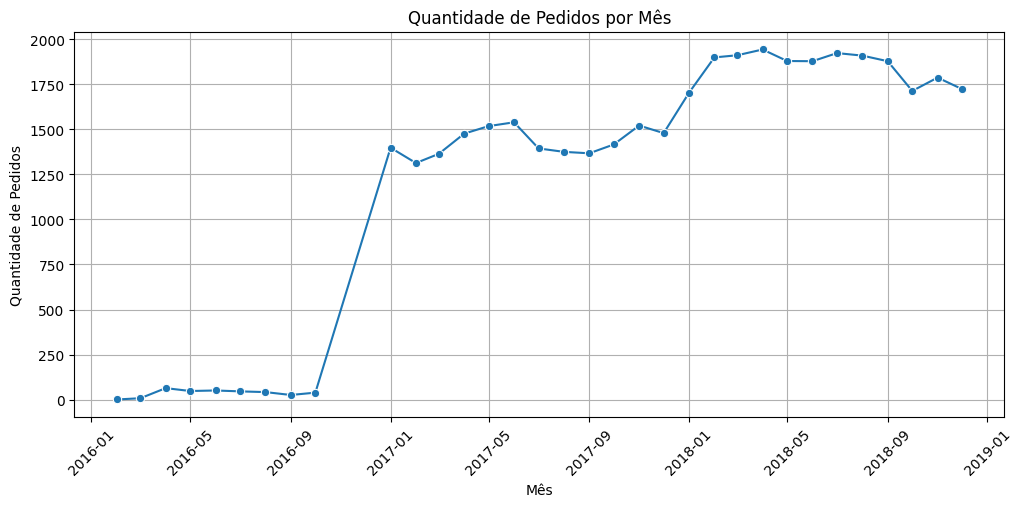

In [27]:
#tabela de visualização evolução mensal pedidos

plt.figure(figsize=(12,5))

sns.lineplot(
    data=pedidos_mensais,
    x='mes',
    y='quantidade_pedidos',
    marker='o'
)

plt.title('Quantidade de Pedidos por Mês')
plt.xlabel('Mês')
plt.ylabel('Quantidade de Pedidos')
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [28]:
# Calculando receita e ticket médio

df_pagamentos.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [31]:
# quantidade de id's

df_pagamentos['order_id'].nunique()

99440

In [33]:
# existe id repetido?

df_pagamentos['order_id'].duplicated().sum()

np.int64(4446)

In [34]:
# visualizar duplicados
pedidos_repetidos = df_pagamentos[
    df_pagamentos['order_id'].duplicated(keep=False)
]

pedidos_repetidos.sort_values('order_id')

,order_id,payment_sequential,payment_type,payment_installments,payment_value
80856,0016dfedd97fc2950e388d2971d718c7,2,voucher,1,17.92
89575,0016dfedd97fc2950e388d2971d718c7,1,credit_card,5,52.63
20036,002f19a65a2ddd70a090297872e6d64e,1,voucher,1,44.11
98894,002f19a65a2ddd70a090297872e6d64e,2,voucher,1,33.18
30155,0071ee2429bc1efdc43aa3e073a5290e,2,voucher,1,92.44
...,...,...,...,...,...
21648,ffa1dd97810de91a03abd7bd76d2fed1,2,voucher,1,418.73
32912,ffa39020fe7c8a3e907320e1bec4b985,1,credit_card,1,7.13
3009,ffa39020fe7c8a3e907320e1bec4b985,2,voucher,1,64.01
75188,ffc730a0615d28ec19f9cad02cb41442,1,credit_card,1,14.76


In [39]:
# soma de pagamentos

valor_formatado = f'{total_pagamentos:,.2f}'
valor_formatado = valor_formatado.replace(',', 'X').replace('.', ',').replace('X', '.')

print(f'Total de pagamentos: R$ {valor_formatado}')

Total de pagamentos: R$ 16.008.872,12


In [42]:
# calcular ticket médio

total_pagamentos = df_pagamentos['payment_value'].sum()

qtde_pedidos = df_orders['order_id'].nunique()

ticket_medio = total_pagamentos / qtde_pedidos

# formatar valor em reais

ticket_formatado = f'{ticket_medio:,.2f}'
ticket_formatado = ticket_formatado.replace(',', 'X').replace('.', ',').replace('X', '.')

print(f'Ticket médio: R$ {ticket_formatado}')

Ticket médio: R$ 160,99


In [62]:
#bases

df_products = pd.read_csv('/olist_products_dataset[1].csv')
df_sellers = pd.read_csv('/olist_sellers_dataset.csv')
df_order_items = pd.read_csv('/olist_order_items_dataset[1].csv')
df_customers = pd.read_csv('/olist_customers_dataset[1].csv')

In [49]:
# juntar itens com produtos
df_analise = df_order_items.merge(
    df_products,
    on='product_id',
    how='left'
)

# juntar com pedidos
df_analise = df_analise.merge(
    df_orders[['order_id', 'customer_id']],
    on='order_id',
    how='left'
)

# juntar com clientes
df_analise = df_analise.merge(
    df_customers[['customer_id', 'customer_city', 'customer_state']],
    on='customer_id',
    how='left'
)

In [50]:
# visualizando

df_analise.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,customer_id,customer_city,customer_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0,3ce436f183e68e07877b285a838db11a,campos dos goytacazes,RJ
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,f6dd3ec061db4e3987629fe6b26e5cce,santa fe do sul,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,6489ae5e4333f3693df5ad4372dab6d3,para de minas,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0,d4eb9395c8c0431ee92fce09860c5a06,atibaia,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0,58dbd0b2d70206bf40e62cd34e84d795,varzea paulista,SP


In [54]:
# analise faturamento

categoria_uf = (
    df_analise.groupby(
        ['customer_state', 'product_category_name']
    )['price']
    .sum()
    .reset_index()
)

categoria_uf.columns = [
    'estado',
    'categoria',
    'faturamento'
]

In [55]:
# participação de cada estado

categoria_uf['participacao_%'] = (
    categoria_uf['faturamento'] /
    categoria_uf.groupby('estado')['faturamento'].transform('sum')
) * 100

categoria_uf = categoria_uf.sort_values(
    ['estado', 'participacao_%'],
    ascending=[True, False]
)

categoria_uf.head(20)

,estado,categoria,faturamento,participacao_%
10,AC,esporte_lazer,1677.46,10.539424
24,AC,relogios_presentes,1389.60,8.730809
3,AC,beleza_saude,1386.58,8.711835
19,AC,moveis_decoracao,1316.44,8.271148
14,AC,informatica_acessorios,1290.48,8.108042
22,AC,pcs,1200.00,7.539559
25,AC,telefonia,1103.96,6.936143
2,AC,bebes,697.84,4.384505
16,AC,livros_interesse_geral,633.80,3.982144
13,AC,ferramentas_jardim,629.00,3.951986


In [72]:
# Remover registros sem categoria ou localização
df_analise['product_category_name'] = (
    df_analise['product_category_name'].fillna('Sem categoria')
)

df_analise['customer_state'] = (
    df_analise['customer_state'].fillna('Não informado')
)

df_analise['customer_city'] = (
    df_analise['customer_city'].fillna('Não informado')
)

# Selecionar as 10 categorias com maior faturamento
top_categorias = (
    df_analise.groupby('product_category_name')['price']
    .sum()
    .nlargest(10)
    .index
)

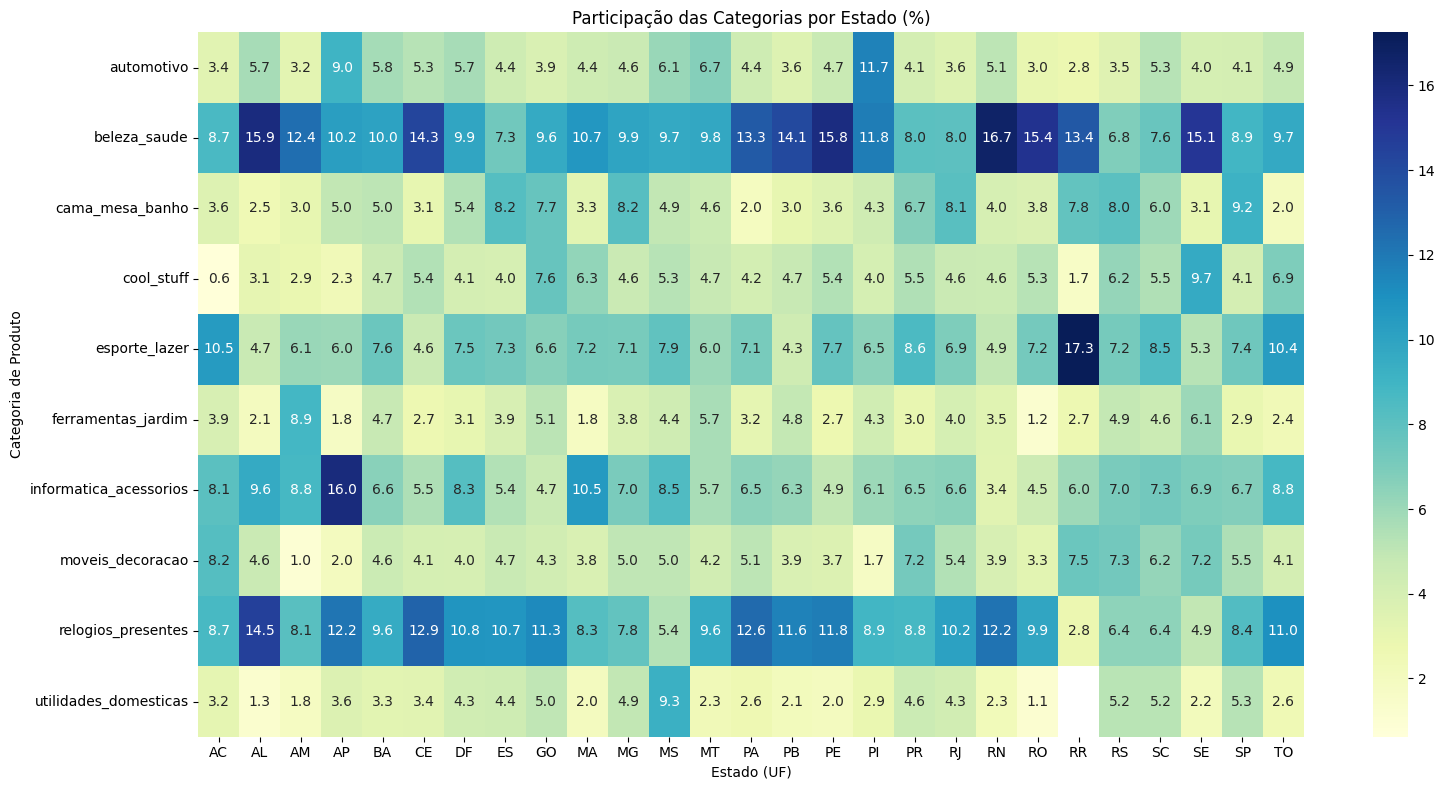

In [73]:
# Agrupar faturamento por estado e categoria
participacao_uf = (
    df_analise.groupby(
        ['customer_state', 'product_category_name']
    )['price']
    .sum()
    .reset_index()
)

# Calcular participação percentual dentro de cada estado
participacao_uf['participacao'] = (
    participacao_uf['price'] /
    participacao_uf.groupby('customer_state')['price'].transform('sum')
) * 100

# Filtrar as 10 principais categorias
participacao_uf = participacao_uf[
    participacao_uf['product_category_name'].isin(top_categorias)
]

# Criar tabela para o gráfico
tabela_uf = participacao_uf.pivot(
    index='product_category_name',
    columns='customer_state',
    values='participacao'
)

# Gerar gráfico
plt.figure(figsize=(16, 8))

sns.heatmap(
    tabela_uf,
    cmap='YlGnBu',
    annot=True,
    fmt='.1f'
)

plt.title('Participação das Categorias por Estado (%)')
plt.xlabel('Estado (UF)')
plt.ylabel('Categoria de Produto')
plt.tight_layout()
plt.show()

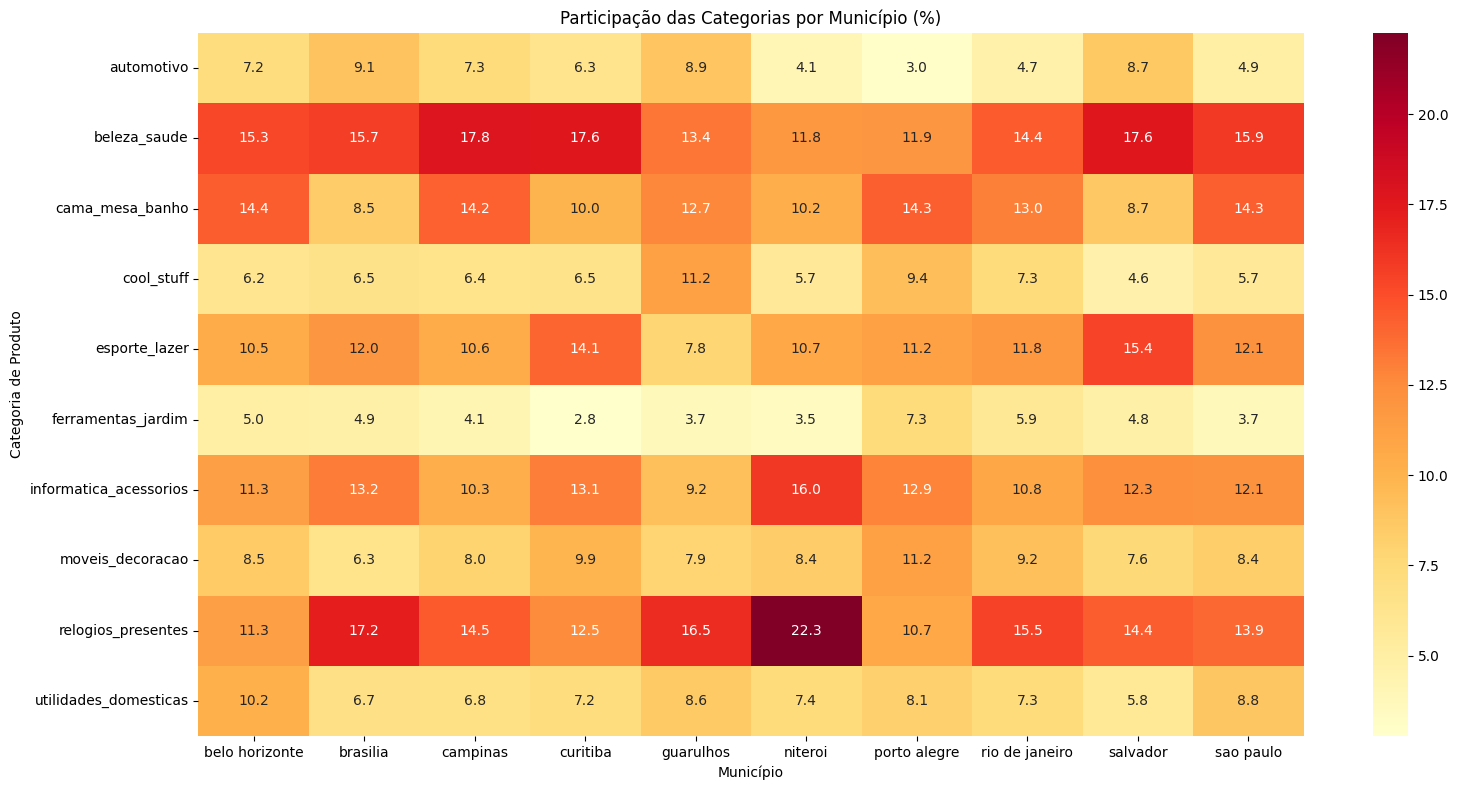

In [74]:
# Identificar os 10 municípios com maior faturamento
top_municipios = (
    df_analise.groupby('customer_city')['price']
    .sum()
    .nlargest(10)
    .index
)

# Filtrar os municípios e categorias selecionados
df_municipios = df_analise[
    (df_analise['customer_city'].isin(top_municipios)) &
    (df_analise['product_category_name'].isin(top_categorias))
]

# Agrupar faturamento por município e categoria
participacao_municipio = (
    df_municipios.groupby(
        ['customer_city', 'product_category_name']
    )['price']
    .sum()
    .reset_index()
)

# Calcular participação percentual dentro de cada município
participacao_municipio['participacao'] = (
    participacao_municipio['price'] /
    participacao_municipio.groupby('customer_city')['price'].transform('sum')
) * 100

# Criar tabela para o gráfico
tabela_municipio = participacao_municipio.pivot(
    index='product_category_name',
    columns='customer_city',
    values='participacao'
)

# Gerar gráfico
plt.figure(figsize=(16, 8))

sns.heatmap(
    tabela_municipio,
    cmap='YlOrRd',
    annot=True,
    fmt='.1f'
)

plt.title('Participação das Categorias por Município (%)')
plt.xlabel('Município')
plt.ylabel('Categoria de Produto')
plt.tight_layout()
plt.show()

In [56]:
# participação cidade

categoria_cidade = (
    df_analise.groupby(
        ['customer_state', 'customer_city', 'product_category_name']
    )['price']
    .sum()
    .reset_index()
)

categoria_cidade.columns = [
    'estado',
    'cidade',
    'categoria',
    'faturamento'
]

categoria_cidade['participacao_%'] = (
    categoria_cidade['faturamento'] /
    categoria_cidade.groupby(
        ['estado', 'cidade']
    )['faturamento'].transform('sum')
) * 100

categoria_cidade.sort_values(
    'faturamento', ascending=False
).head(20)

,estado,cidade,categoria,faturamento,participacao_%
24286,SP,sao paulo,beleza_saude,189361.87,10.039599
24288,SP,sao paulo,cama_mesa_banho,170705.41,9.050469
24340,SP,sao paulo,relogios_presentes,165897.46,8.795561
24319,SP,sao paulo,informatica_acessorios,144635.68,7.668303
24307,SP,sao paulo,esporte_lazer,144533.26,7.662873
24345,SP,sao paulo,utilidades_domesticas,104820.45,5.557377
24329,SP,sao paulo,moveis_decoracao,100033.05,5.303558
13942,RJ,rio de janeiro,relogios_presentes,93028.74,9.482771
13891,RJ,rio de janeiro,beleza_saude,86558.34,8.823219
13893,RJ,rio de janeiro,cama_mesa_banho,77871.29,7.937715


In [57]:
# produtos top performances

# agrupando produtos

produtos_top = (
    df_analise.groupby(
        ['product_id', 'product_category_name']
    )
    .agg(
        quantidade_vendida=('order_item_id', 'count'),
        faturamento=('price', 'sum'),
        pedidos=('order_id', 'nunique')
    )
    .reset_index()
)

In [58]:
# ordenando por faturamento

produtos_top = produtos_top.sort_values(
    'faturamento',
    ascending=False
)

produtos_top.head(10)

,product_id,product_category_name,quantidade_vendida,faturamento,pedidos
23650,bb50f2e236e5eea0100680137654686c,beleza_saude,195,63885.00,187
13813,6cdd53843498f92890544667809f1595,beleza_saude,156,54730.20,151
27114,d6160fb7873f184099d9bc95e30376af,pcs,35,48899.34,35
26545,d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,343,47214.51,323
19394,99a4788cb24856965c36a24e339b6058,cama_mesa_banho,488,43025.56,467
7905,3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,274,41082.60,255
4904,25c38557cf793876c5abdd5931f922db,bebes,38,38907.32,38
12129,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,37733.90,63
10665,53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,323,37683.42,306
21724,aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,527,37608.90,431


In [59]:
# mais vendidos

produtos_mais_vendidos = produtos_top.sort_values(
    'quantidade_vendida',
    ascending=False
)

produtos_mais_vendidos.head(10)

,product_id,product_category_name,quantidade_vendida,faturamento,pedidos
21724,aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,527,37608.90,431
19394,99a4788cb24856965c36a24e339b6058,cama_mesa_banho,488,43025.56,467
8456,422879e10f46682990de24d770e7f83d,ferramentas_jardim,484,26577.22,352
7231,389d119b48cf3043d311335e499d9c6b,ferramentas_jardim,392,21440.59,311
6950,368c6c730842d78016ad823897a372db,ferramentas_jardim,388,21056.80,291
10638,53759a2ecddad2bb87a079a1f1519f73,ferramentas_jardim,373,20387.20,287
26545,d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,343,47214.51,323
10665,53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,323,37683.42,306
2743,154e7e31ebfa092203795c972e5804a6,beleza_saude,281,6325.19,269
7905,3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,274,41082.60,255


In [65]:
# sellers top performance

# agrupando tabelas

df_sellers_analise = df_order_items.merge(
    df_sellers,
    on='seller_id',
    how='left')

# indicadores por vendedor

sellers_top = (
    df_sellers_analise.groupby(
        ['seller_id', 'seller_city', 'seller_state']
    )
    .agg(
        quantidade_vendida=('order_item_id', 'count'),
        quantidade_pedidos=('order_id', 'nunique'),
        faturamento=('price', 'sum')
    )
    .reset_index()
)

# top 10 vendedores por faturamento

sellers_top = sellers_top.sort_values(
    'faturamento',
    ascending=False
)

sellers_top.head(10)

,seller_id,seller_city,seller_state,quantidade_vendida,quantidade_pedidos,faturamento
857,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1156,1132,229472.63
1013,53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,410,358,222776.05
881,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1987,1806,200472.92
3024,fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,586,585,194042.03
1535,7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,1364,982,187923.89
1560,7e93a43ef30c4f03f38b393420bc753a,barueri,SP,340,336,176431.87
2643,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1551,1314,160236.57
1505,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1171,1160,141745.53
192,1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,1428,915,138968.55
1824,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1499,1287,135171.70


In [66]:
# top 10 vendedores por quantidade de itens

sellers_top.sort_values(
    'quantidade_vendida',
    ascending=False
).head(10)

,seller_id,seller_city,seller_state,quantidade_vendida,quantidade_pedidos,faturamento
1235,6560211a19b47992c3666cc44a7e94c0,sao paulo,SP,2033,1854,123304.83
881,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1987,1806,200472.92
368,1f50f920176fa81dab994f9023523100,sao jose do rio preto,SP,1931,1404,106939.21
2481,cc419e0650a3c5ba77189a1882b7556a,santo andre,SP,1775,1706,104288.42
2643,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1551,1314,160236.57
1824,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1499,1287,135171.70
192,1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,1428,915,138968.55
1535,7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,1364,982,187923.89
2836,ea8482cd71df3c1969d7b9473ff13abc,sao paulo,SP,1203,1146,37177.52
1505,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1171,1160,141745.53


In [67]:
# top 10 vendedores por quantidade de pedido

sellers_top.sort_values(
    'quantidade_pedidos',
    ascending=False
).head(10)

,seller_id,seller_city,seller_state,quantidade_vendida,quantidade_pedidos,faturamento
1235,6560211a19b47992c3666cc44a7e94c0,sao paulo,SP,2033,1854,123304.83
881,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1987,1806,200472.92
2481,cc419e0650a3c5ba77189a1882b7556a,santo andre,SP,1775,1706,104288.42
368,1f50f920176fa81dab994f9023523100,sao jose do rio preto,SP,1931,1404,106939.21
2643,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1551,1314,160236.57
1824,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1499,1287,135171.70
1505,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1171,1160,141745.53
2836,ea8482cd71df3c1969d7b9473ff13abc,sao paulo,SP,1203,1146,37177.52
857,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1156,1132,229472.63
731,3d871de0142ce09b7081e2b9d1733cb1,campo limpo paulista,SP,1147,1080,94914.20


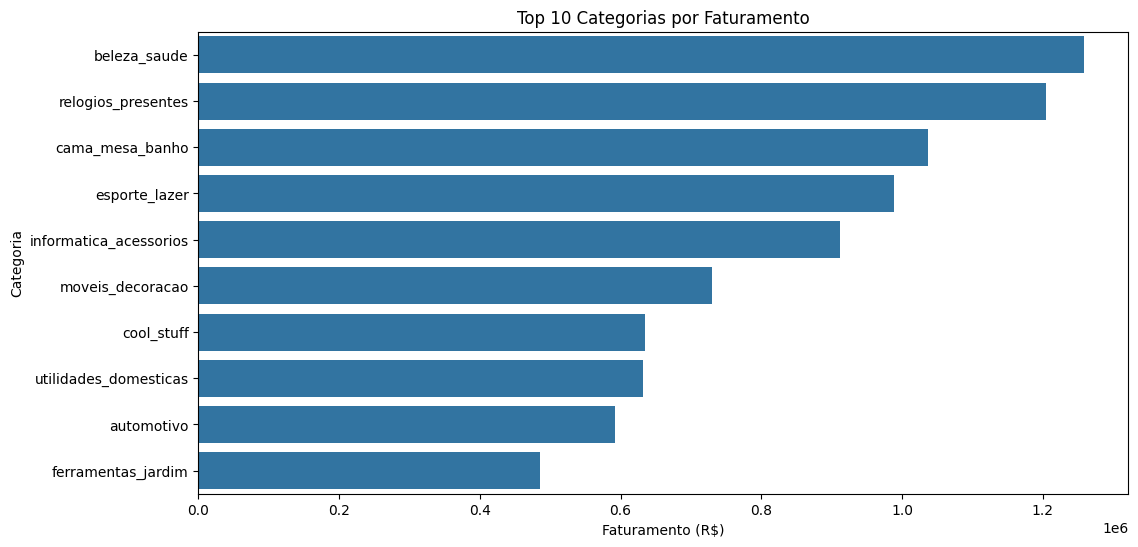

In [69]:
# top 10 categorias por faturamento

top_categorias = (
    df_analise.groupby('product_category_name')['price']
    .sum()
    .nlargest(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categorias,
    x='price',
    y='product_category_name'
)

plt.title('Top 10 Categorias por Faturamento')
plt.xlabel('Faturamento (R$)')
plt.ylabel('Categoria')
plt.show()

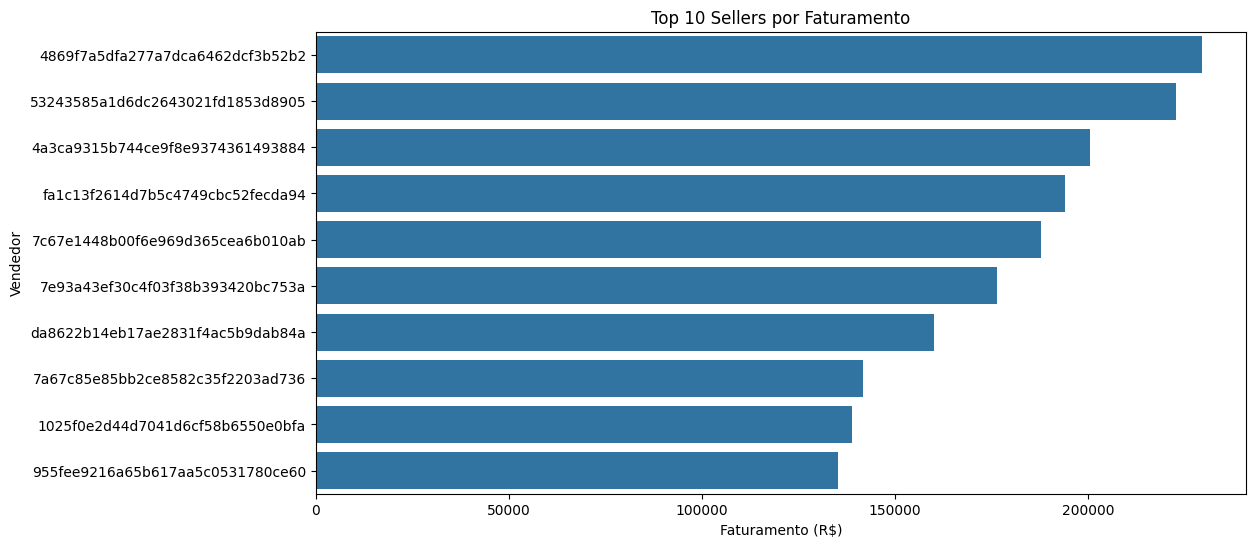

In [70]:
# top 10 vendedores

top_sellers = sellers_top.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_sellers,
    x='faturamento',
    y='seller_id'
)

plt.title('Top 10 Sellers por Faturamento')
plt.xlabel('Faturamento (R$)')
plt.ylabel('Vendedor')
plt.show()